### 0. 데이터 불러오기

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("harpartapsingh13/ai-companion-dependency-prediction-dataset")

print("Path to dataset files:", path)

c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\82102\.cache\kagglehub\datasets\harpartapsingh13\ai-companion-dependency-prediction-dataset\versions\1


In [2]:
import os

# 다운로드된 폴더 안 파일 목록 확인
for f in os.listdir(path):
    print(f)

ai_companion_dependency_dataset.csv


In [3]:
import pandas as pd

file_name = "ai_companion_dependency_dataset.csv"
df = pd.read_csv(os.path.join(path, file_name))

df.head()

,user_id,age,gender,occupation_status,education_level,income_level,relationship_status,living_situation,country_region,ai_chatbot_platform,...,sleep_hours,sleep_quality_score,exercise_hours_weekly,anxiety_score,depression_score,stress_score,self_esteem_score,academic_or_work_performance_change,therapy_attendance,dependency_risk_label
0,U0001,21,Male,Employed Full-Time,High School,Lower-Middle,In a Relationship,With Partner,South America,ChatGPT,...,7.3,9.1,3.3,3.5,3.0,1.0,9.5,Improved,No,Low
1,U0002,34,Male,Student,Graduate,Upper-Middle,Single,Alone,North America,Character.AI,...,7.5,3.5,0.9,4.6,2.4,5.2,4.7,Same,No,Moderate
2,U0003,43,Male,Employed Full-Time,Graduate,Low,Single,Alone,Europe,Character.AI,...,6.8,8.3,7.6,1.0,1.0,3.2,7.2,Improved,No,Low
3,U0004,29,Non-binary,Employed Full-Time,Graduate,Low,Single,With Family,Asia,ChatGPT,...,9.5,8.9,7.4,2.7,1.5,2.6,9.0,Improved,No,Low
4,U0005,25,Female,Student,Graduate,Upper-Middle,In a Relationship,With Roommates,South America,ChatGPT,...,8.5,10.0,6.5,1.0,1.0,1.0,9.9,Improved,No,Low


In [12]:
df.columns

Index(['user_id', 'age', 'gender', 'occupation_status', 'education_level',
       'income_level', 'relationship_status', 'living_situation',
       'country_region', 'ai_chatbot_platform', 'primary_use_case',
       'daily_ai_chat_hours', 'human_social_interaction_hours',
       'social_media_hours_daily', 'screen_time_total_hours',
       'number_of_close_friends', 'loneliness_score',
       'emotional_attachment_score', 'real_relationship_satisfaction',
       'prefers_ai_over_humans', 'sleep_hours', 'sleep_quality_score',
       'exercise_hours_weekly', 'anxiety_score', 'depression_score',
       'stress_score', 'self_esteem_score',
       'academic_or_work_performance_change', 'therapy_attendance',
       'dependency_risk_label'],
      dtype='str')

### 1. 라벨 검증

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

=== Decision Tree ===
Accuracy: 0.71


,precision,recall,f1-score,support
High,0.694,0.729,0.711,59.00
Low,0.763,0.865,0.811,104.00
Moderate,0.450,0.243,0.316,37.00
accuracy,0.710,0.710,0.710,0.71
macro avg,0.635,0.612,0.612,200.00
weighted avg,0.684,0.710,0.690,200.00


,예측_High,예측_Low,예측_Moderate
실제_High,43,12,4
실제_Low,7,90,7
실제_Moderate,12,16,9


,importance
daily_ai_chat_hours,0.931320
prefers_ai_binary,0.049657
use_case_Learning,0.009566
use_case_Productivity/Work,0.009456
use_case_Companionship,0.000000
use_case_Entertainment,0.000000
use_case_Therapy-Substitute,0.000000


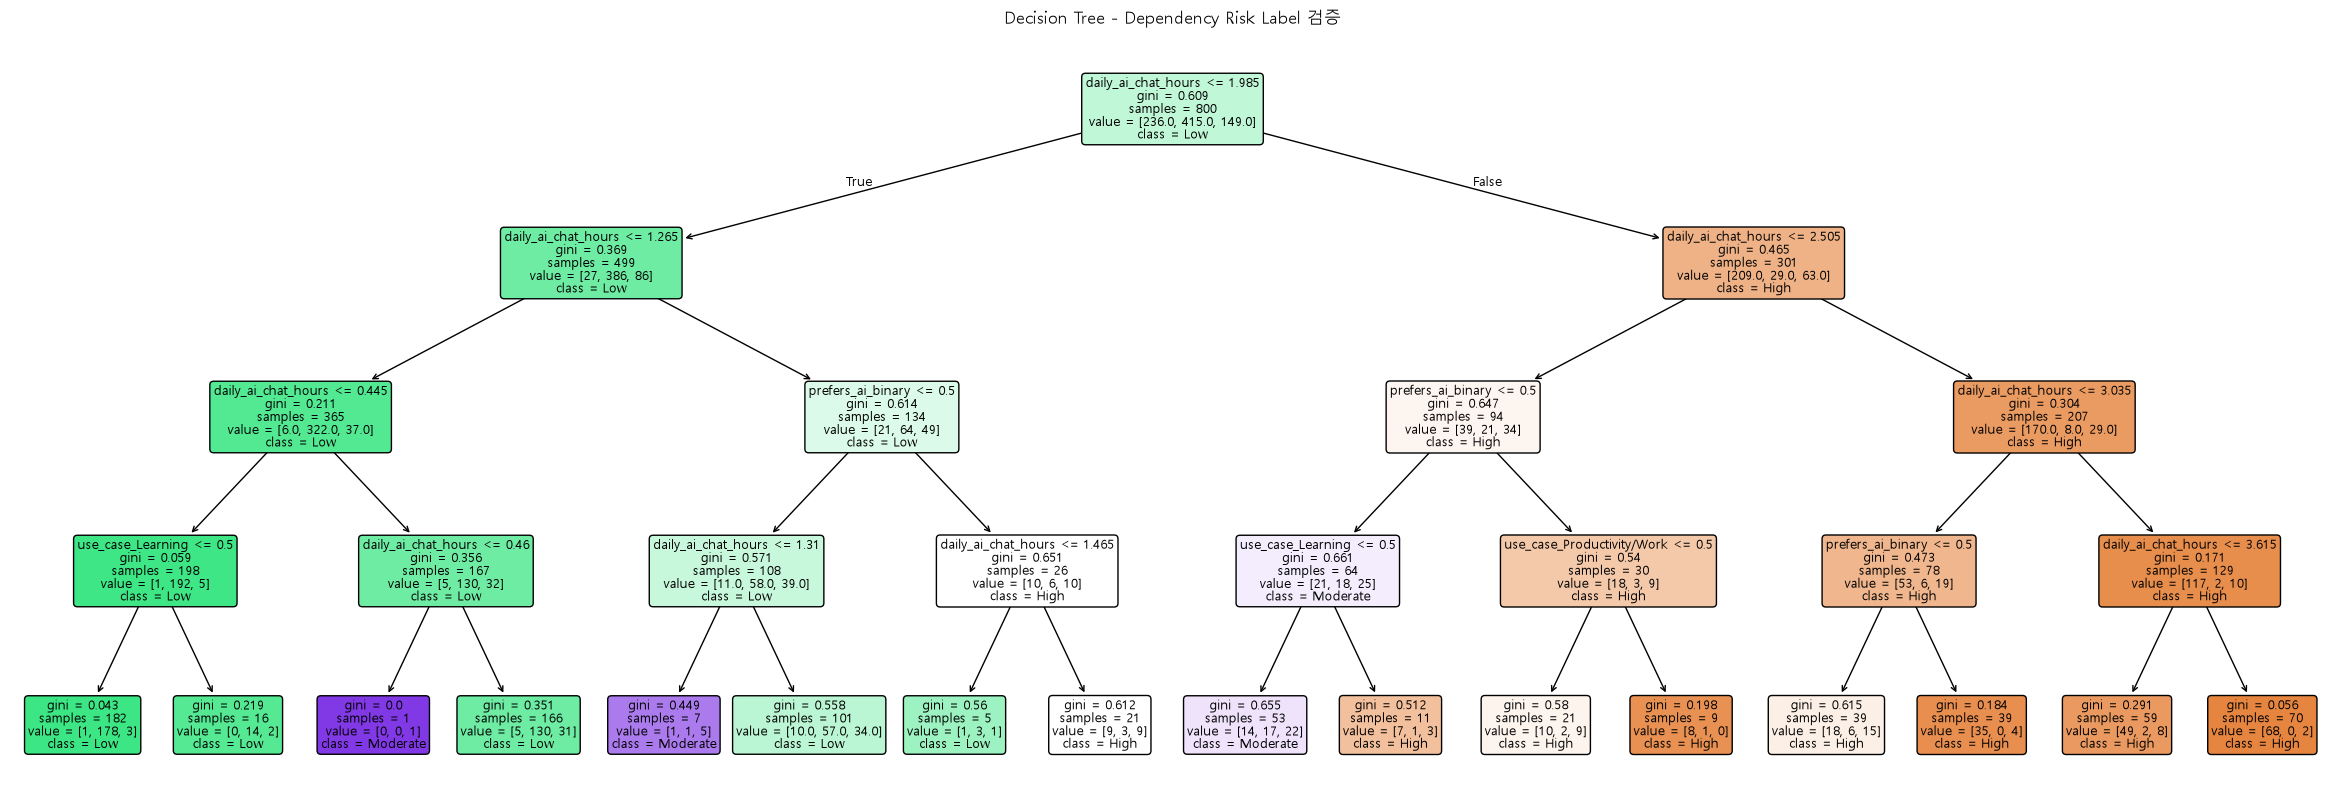


=== Logistic Regression ===
Accuracy: 0.715


,precision,recall,f1-score,support
High,0.700,0.712,0.706,59.000
Low,0.762,0.894,0.823,104.000
Moderate,0.444,0.216,0.291,37.000
accuracy,0.715,0.715,0.715,0.715
macro avg,0.636,0.607,0.607,200.000
weighted avg,0.685,0.715,0.690,200.000


,예측_High,예측_Low,예측_Moderate
실제_High,42,12,5
실제_Low,6,93,5
실제_Moderate,12,17,8


In [ ]:
# ── 1. 세 변수 + 라벨만 추출, 인코딩 ──────────────────────────
check_df = df[['daily_ai_chat_hours', 'prefers_ai_over_humans',
                'primary_use_case', 'dependency_risk_label']].copy()

check_df['prefers_ai_binary'] = check_df['prefers_ai_over_humans'].map({'Yes': 1, 'No': 0})
use_case_dummies = pd.get_dummies(check_df['primary_use_case'], prefix='use_case')
check_df = pd.concat([check_df, use_case_dummies], axis=1)

feature_cols = ['daily_ai_chat_hours', 'prefers_ai_binary'] + list(use_case_dummies.columns)
X = check_df[feature_cols]
y = check_df['dependency_risk_label']

# ── 2. train/test 분리 ────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ── 3. 결정트리 ────────────────────────────────────────────────
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("=== Decision Tree ===")
print("Accuracy:", accuracy_score(y_test, tree_pred))

# classification_report → DataFrame
tree_report_df = pd.DataFrame(
    classification_report(y_test, tree_pred, output_dict=True)
).T.round(3)
display(tree_report_df)

# confusion_matrix → DataFrame
tree_cm_df = pd.DataFrame(
    confusion_matrix(y_test, tree_pred, labels=tree.classes_),
    index=[f'실제_{c}' for c in tree.classes_],
    columns=[f'예측_{c}' for c in tree.classes_]
)
display(tree_cm_df)

# feature importance → DataFrame
tree_importance_df = pd.Series(
    tree.feature_importances_, index=feature_cols
).sort_values(ascending=False).to_frame('importance')
display(tree_importance_df)

# 트리 모형 그래프 출력
plt.figure(figsize=(30, 10))
plot_tree(
    tree,
    feature_names=feature_cols,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree - Dependency Risk Label 검증")
plt.show()

# ── 4. 로지스틱 회귀 ────────────────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[['daily_ai_chat_hours']])
X_test_scaled = scaler.transform(X_test[['daily_ai_chat_hours']])

X_train_logit = X_train.copy()
X_test_logit = X_test.copy()
X_train_logit['daily_ai_chat_hours'] = X_train_scaled
X_test_logit['daily_ai_chat_hours'] = X_test_scaled

logit = LogisticRegression(max_iter=1000)
logit.fit(X_train_logit, y_train)
logit_pred = logit.predict(X_test_logit)

print("\n=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, logit_pred))

logit_report_df = pd.DataFrame(
    classification_report(y_test, logit_pred, output_dict=True)
).T.round(3)
display(logit_report_df)

logit_cm_df = pd.DataFrame(
    confusion_matrix(y_test, logit_pred, labels=logit.classes_),
    index=[f'실제_{c}' for c in logit.classes_],
    columns=[f'예측_{c}' for c in logit.classes_]
)
display(logit_cm_df)

### 2. 데이터 전처리

In [47]:
df.describe()

,age,daily_ai_chat_hours,human_social_interaction_hours,social_media_hours_daily,screen_time_total_hours,number_of_close_friends,loneliness_score,emotional_attachment_score,real_relationship_satisfaction,sleep_hours,sleep_quality_score,exercise_hours_weekly,anxiety_score,depression_score,stress_score,self_esteem_score
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,29.940000,1.613470,3.98939,2.508770,6.093740,4.096000,5.072900,4.562700,6.000400,7.045000,6.535400,4.032600,4.543200,4.115100,5.014100,5.977000
std,9.033493,1.309653,1.51918,1.369145,2.625688,2.118318,2.443298,2.466711,2.322015,1.177328,2.084147,1.945184,2.211372,2.267846,2.054174,2.183726
min,15.000000,0.000000,0.00000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,3.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,22.000000,0.500000,2.94750,1.520000,4.140000,3.000000,3.200000,2.500000,4.400000,6.200000,5.200000,2.700000,2.900000,2.200000,3.500000,4.600000
50%,30.000000,1.440000,3.93500,2.510000,5.770000,4.000000,5.100000,4.500000,6.050000,7.100000,6.500000,4.000000,4.500000,4.000000,5.000000,6.000000
75%,38.000000,2.530000,5.00250,3.420000,7.805000,5.000000,6.800000,6.225000,7.800000,7.800000,8.125000,5.400000,6.000000,5.700000,6.400000,7.500000
max,44.000000,6.520000,9.75000,6.700000,14.300000,11.000000,10.000000,10.000000,10.000000,10.000000,10.000000,9.800000,10.000000,10.000000,10.000000,10.000000


In [49]:
print(df.describe().columns)
print("")
print(df.describe(include='object').columns)

Index(['age', 'daily_ai_chat_hours', 'human_social_interaction_hours',
       'social_media_hours_daily', 'screen_time_total_hours',
       'number_of_close_friends', 'loneliness_score',
       'emotional_attachment_score', 'real_relationship_satisfaction',
       'sleep_hours', 'sleep_quality_score', 'exercise_hours_weekly',
       'anxiety_score', 'depression_score', 'stress_score',
       'self_esteem_score'],
      dtype='str')

Index(['user_id', 'gender', 'occupation_status', 'education_level',
       'income_level', 'relationship_status', 'living_situation',
       'country_region', 'ai_chatbot_platform', 'primary_use_case',
       'prefers_ai_over_humans', 'academic_or_work_performance_change',
       'therapy_attendance', 'dependency_risk_label'],
      dtype='str')


C:\Users\82102\AppData\Local\Temp\ipykernel_18684\211514370.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include='object').columns)


In [51]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [52]:
# ── 1) Feature/Target 선정 ──────────────────────────────────────
exclude_cols = ['user_id', 'daily_ai_chat_hours']  # 식별자 + 순환성 위험 변수
target_col = 'dependency_risk_label'

feature_df = df.drop(columns=exclude_cols + [target_col])
y = df[target_col]

# ── 2) 카디널리티 높은 변수 그룹화 ────────────────────────────
# country_region: Oceania(1.8%) → 'Other'로 통합
feature_df['country_region_grouped'] = feature_df['country_region'].replace(
    {'Oceania': 'Other'}
)
feature_df = feature_df.drop(columns=['country_region'])

# occupation_status: 모든 범주 5% 이상 → 그룹화 없이 원형 유지

# ── 3) 범주형 변수 인코딩 ─────────────────────────────────────
# 3-1. 이진 변수
binary_cols = ['prefers_ai_over_humans', 'therapy_attendance']
for col in binary_cols:
    feature_df[col] = feature_df[col].map({'Yes': 1, 'No': 0})

# 3-2. 순서형 변수 (Ordinal Encoding)
# education_level: High School < Undergraduate < Graduate < Postgraduate
# income_level: Low < Lower-Middle < Upper-Middle < High
ordinal_cols = ['education_level', 'income_level']
ordinal_categories = [
    ['High School', 'Undergraduate', 'Graduate', 'Postgraduate'],
    ['Low', 'Lower-Middle', 'Upper-Middle', 'High']
]

ord_encoder = OrdinalEncoder(categories=ordinal_categories)
feature_df[ordinal_cols] = ord_encoder.fit_transform(feature_df[ordinal_cols])

# 3-3. 명목형 변수 (One-Hot Encoding)
# academic_or_work_performance_change는 값 구성 확인 후 순서형 여부 재검토 필요 (일단 명목형으로 처리)
nominal_cols = ['gender', 'occupation_status', 'relationship_status',
                 'living_situation', 'country_region_grouped',
                 'ai_chatbot_platform', 'primary_use_case',
                 'academic_or_work_performance_change']

feature_df = pd.get_dummies(feature_df, columns=nominal_cols, drop_first=True)

# ── 4) Train/Test 분리 ──────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    feature_df, y, test_size=0.2, random_state=42, stratify=y
)

# ── 5) 수치형 변수 스케일링 ──────────────────────────────────
numeric_cols = ['age', 'human_social_interaction_hours', 'social_media_hours_daily',
                 'screen_time_total_hours', 'number_of_close_friends',
                 'loneliness_score', 'emotional_attachment_score',
                 'real_relationship_satisfaction', 'sleep_hours',
                 'sleep_quality_score', 'exercise_hours_weekly',
                 'anxiety_score', 'depression_score', 'stress_score',
                 'self_esteem_score'] + ordinal_cols

scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# ── 6) 다중공선성 확인 (VIF) ────────────────────────────────────
X_train_vif = X_train.astype(float)
vif_df = pd.DataFrame({
    'feature': X_train_vif.columns,
    'VIF': [variance_inflation_factor(X_train_vif.values, i)
            for i in range(X_train_vif.shape[1])]
})
display(vif_df.sort_values('VIF', ascending=False))

# ── 7) 최종 데이터셋 확인 ────────────────────────────────────────
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train 분포:\n", y_train.value_counts(normalize=True).round(3))
print("y_test 분포:\n", y_test.value_counts(normalize=True).round(3))

,feature,VIF
28,relationship_status_Single,6.882900
8,emotional_attachment_score,4.915678
5,screen_time_total_hours,4.562414
26,relationship_status_In a Relationship,4.397172
32,country_region_grouped_Asia,4.382772
7,loneliness_score,4.220925
15,depression_score,3.987877
45,academic_or_work_performance_change_Improved,3.961890
14,anxiety_score,3.778967
46,academic_or_work_performance_change_Same,3.729731


X_train shape: (800, 47)
X_test shape: (200, 47)
y_train 분포:
 dependency_risk_label
Low         0.519
High        0.295
Moderate    0.186
Name: proportion, dtype: float64
y_test 분포:
 dependency_risk_label
Low         0.520
High        0.295
Moderate    0.185
Name: proportion, dtype: float64


### 3. 모델링(without PCA)

In [53]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report,
                               confusion_matrix, f1_score)

In [ ]:
# ── 1) 베이스라인 모델 — 다항 로지스틱 회귀 ──────────────────────
baseline_logit = LogisticRegression(max_iter=1000)
baseline_logit.fit(X_train, y_train)
baseline_pred = baseline_logit.predict(X_test)

print("=== 1) Baseline Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, baseline_pred))
baseline_report = pd.DataFrame(
    classification_report(y_test, baseline_pred, output_dict=True)
).T.round(3)
display(baseline_report)

baseline_cm = pd.DataFrame(
    confusion_matrix(y_test, baseline_pred, labels=baseline_logit.classes_),
    index=[f'실제_{c}' for c in baseline_logit.classes_],
    columns=[f'예측_{c}' for c in baseline_logit.classes_]
)
display(baseline_cm)

# ── 2) Random Forest ─────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight='balanced',   # ── 5) 클래스 불균형 대응 ──
    random_state=42
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("\n=== 3) Random Forest ===")
print("Accuracy:", accuracy_score(y_test, rf_pred))
rf_report = pd.DataFrame(
    classification_report(y_test, rf_pred, output_dict=True)
).T.round(3)
display(rf_report)

rf_cm = pd.DataFrame(
    confusion_matrix(y_test, rf_pred, labels=rf.classes_),
    index=[f'실제_{c}' for c in rf.classes_],
    columns=[f'예측_{c}' for c in rf.classes_]
)
display(rf_cm)

rf_importance = pd.Series(
    rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False).head(15).to_frame('importance')
display(rf_importance)

# ── 3) Gradient Boosting ─────────────────────────────────────────
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("\n=== 4) Gradient Boosting ===")
print("Accuracy:", accuracy_score(y_test, gb_pred))
gb_report = pd.DataFrame(
    classification_report(y_test, gb_pred, output_dict=True)
).T.round(3)
display(gb_report)

gb_cm = pd.DataFrame(
    confusion_matrix(y_test, gb_pred, labels=gb.classes_),
    index=[f'실제_{c}' for c in gb.classes_],
    columns=[f'예측_{c}' for c in gb.classes_]
)
display(gb_cm)

gb_importance = pd.Series(
    gb.feature_importances_, index=X_train.columns
).sort_values(ascending=False).head(15).to_frame('importance')
display(gb_importance)

# ── 4) 교차검증 — Stratified K-Fold ──────────────────────────────
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model in [
    ('Logistic', LogisticRegression(max_iter=1000)),
    ('RandomForest', RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              class_weight='balanced', random_state=42)),
    ('GradientBoosting', GradientBoostingClassifier(n_estimators=200,
                                                       learning_rate=0.05, random_state=42))
]:
    scores = []
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        scores.append(f1_score(y_val, pred, average='macro'))
    cv_results[name] = scores

cv_summary = pd.DataFrame(cv_results)
print("\n=== 6) Cross-Validation (5-Fold, Macro F1) ===")
display(cv_summary)
display(cv_summary.mean().round(3).to_frame('mean_macro_f1'))

# ── 5) 모델별 성능 비교 (Test set 기준) ──────────────────────────
comparison = pd.DataFrame({
    'Accuracy': [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    'Macro F1': [
        f1_score(y_test, baseline_pred, average='macro'),
        f1_score(y_test, rf_pred, average='macro'),
        f1_score(y_test, gb_pred, average='macro')
    ],
    'Weighted F1': [
        f1_score(y_test, baseline_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, gb_pred, average='weighted')
    ]
}, index=['Logistic Regression', 'Random Forest', 'Gradient Boosting']).round(3)

print("\n=== 7) 모델별 최종 성능 비교 ===")
display(comparison)

=== 1) Baseline Logistic Regression ===
Accuracy: 0.76


,precision,recall,f1-score,support
High,0.830,0.746,0.786,59.00
Low,0.858,0.875,0.867,104.00
Moderate,0.415,0.459,0.436,37.00
accuracy,0.760,0.760,0.760,0.76
macro avg,0.701,0.693,0.696,200.00
weighted avg,0.768,0.760,0.763,200.00


,예측_High,예측_Low,예측_Moderate
실제_High,44,3,12
실제_Low,1,91,12
실제_Moderate,8,12,17



=== 3) Random Forest ===
Accuracy: 0.775


,precision,recall,f1-score,support
High,0.896,0.729,0.804,59.000
Low,0.965,0.798,0.874,104.000
Moderate,0.439,0.784,0.563,37.000
accuracy,0.775,0.775,0.775,0.775
macro avg,0.767,0.770,0.747,200.000
weighted avg,0.847,0.775,0.796,200.000


...


=== 6) Cross-Validation (5-Fold, Macro F1) ===


,Logistic,RandomForest,GradientBoosting
0,0.739686,0.763613,0.725064
1,0.726595,0.767377,0.690509
2,0.703251,0.745275,0.765970
3,0.764090,0.765106,0.772166
4,0.802024,0.789982,0.712697


,mean_macro_f1
Logistic,0.747
RandomForest,0.766
GradientBoosting,0.733



=== 7) 모델별 최종 성능 비교 ===


,Accuracy,Macro F1,Weighted F1
Logistic Regression,0.760,0.696,0.763
Random Forest,0.775,0.747,0.796
Gradient Boosting,0.765,0.711,0.771


### 4. 모델링(with PCA)

In [55]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

90% 설명분산 도달 주성분 개수: 30


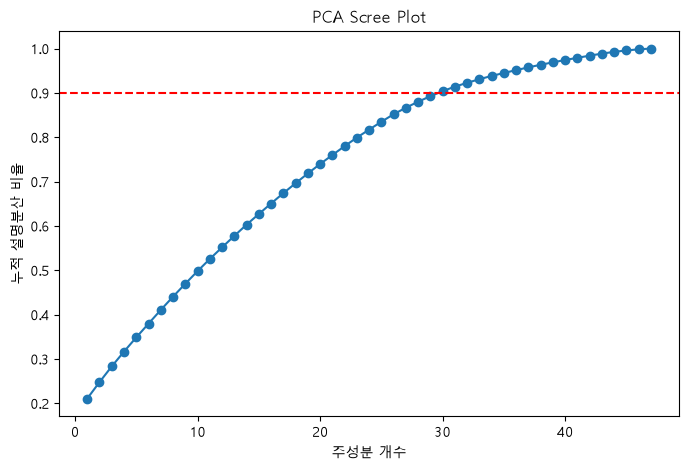

X_train shape: (800, 30)
X_test shape: (200, 30)
y_train 분포:
 dependency_risk_label
Low         0.519
High        0.295
Moderate    0.186
Name: proportion, dtype: float64
y_test 분포:
 dependency_risk_label
Low         0.520
High        0.295
Moderate    0.185
Name: proportion, dtype: float64


In [57]:
# ── 1) Feature/Target 선정 ──────────────────────────────────────
exclude_cols = ['user_id', 'daily_ai_chat_hours']  # 식별자 + 순환성 위험 변수
target_col = 'dependency_risk_label'

feature_df = df.drop(columns=exclude_cols + [target_col])
y = df[target_col]

# ── 2) 카디널리티 높은 변수 그룹화 ────────────────────────────
# country_region: Oceania(1.8%) → 'Other'로 통합
feature_df['country_region_grouped'] = feature_df['country_region'].replace(
    {'Oceania': 'Other'}
)
feature_df = feature_df.drop(columns=['country_region'])

# occupation_status: 모든 범주 5% 이상 → 그룹화 없이 원형 유지

# ── 3) 범주형 변수 인코딩 ─────────────────────────────────────
# 3-1. 이진 변수
binary_cols = ['prefers_ai_over_humans', 'therapy_attendance']
for col in binary_cols:
    feature_df[col] = feature_df[col].map({'Yes': 1, 'No': 0})

# 3-2. 순서형 변수 (Ordinal Encoding)
# education_level: High School < Undergraduate < Graduate < Postgraduate
# income_level: Low < Lower-Middle < Upper-Middle < High
ordinal_cols = ['education_level', 'income_level']
ordinal_categories = [
    ['High School', 'Undergraduate', 'Graduate', 'Postgraduate'],
    ['Low', 'Lower-Middle', 'Upper-Middle', 'High']
]

ord_encoder = OrdinalEncoder(categories=ordinal_categories)
feature_df[ordinal_cols] = ord_encoder.fit_transform(feature_df[ordinal_cols])

# 3-3. 명목형 변수 (One-Hot Encoding)
# academic_or_work_performance_change는 값 구성 확인 후 순서형 여부 재검토 필요 (일단 명목형으로 처리)
nominal_cols = ['gender', 'occupation_status', 'relationship_status',
                 'living_situation', 'country_region_grouped',
                 'ai_chatbot_platform', 'primary_use_case',
                 'academic_or_work_performance_change']

feature_df = pd.get_dummies(feature_df, columns=nominal_cols, drop_first=True)

# ── 4) 스케일링 (PCA 전 필수 — 단위 다른 변수 간 영향력 균등화) ──
scaler = StandardScaler()
feature_scaled = scaler.fit_transform(feature_df)

# ── 5) PCA — 주성분 개수 결정 (설명분산 90% 기준) ──────────────────
pca_full = PCA()
pca_full.fit(feature_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.argmax(cum_var >= 0.90) + 1
print(f"90% 설명분산 도달 주성분 개수: {n_components}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(y=0.90, color='r', linestyle='--')
plt.xlabel('주성분 개수')
plt.ylabel('누적 설명분산 비율')
plt.title('PCA Scree Plot')
plt.show()

# ── 최종 PCA 적용 ────────────────────────────────────────────
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(feature_scaled)

X_pca_df = pd.DataFrame(
    X_pca, columns=[f'PC{i+1}' for i in range(n_components)], index=feature_df.index
)

# ── 6) Train/Test 분리 (PCA 적용 완료된 데이터 기준) ────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_pca_df, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train 분포:\n", y_train.value_counts(normalize=True).round(3))
print("y_test 분포:\n", y_test.value_counts(normalize=True).round(3))

In [58]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report,
                               confusion_matrix, f1_score)


In [59]:
# ── 1) 베이스라인 모델 — 다항 로지스틱 회귀 ──────────────────────
logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, y_train)
logit_pred = logit.predict(X_test)

print("=== a. Logistic Regression (PCA) ===")
print("Accuracy:", accuracy_score(y_test, logit_pred))
logit_report = pd.DataFrame(
    classification_report(y_test, logit_pred, output_dict=True)
).T.round(3)
display(logit_report)

logit_cm = pd.DataFrame(
    confusion_matrix(y_test, logit_pred, labels=logit.classes_),
    index=[f'실제_{c}' for c in logit.classes_],
    columns=[f'예측_{c}' for c in logit.classes_]
)
display(logit_cm)

# ── 2) Random Forest ─────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("\n=== b. Random Forest (PCA) ===")
print("Accuracy:", accuracy_score(y_test, rf_pred))
rf_report = pd.DataFrame(
    classification_report(y_test, rf_pred, output_dict=True)
).T.round(3)
display(rf_report)

rf_cm = pd.DataFrame(
    confusion_matrix(y_test, rf_pred, labels=rf.classes_),
    index=[f'실제_{c}' for c in rf.classes_],
    columns=[f'예측_{c}' for c in rf.classes_]
)
display(rf_cm)

rf_importance = pd.Series(
    rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False).to_frame('importance')
display(rf_importance)


# ── 3) Gradient Boosting ─────────────────────────────────────────
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("\n=== c. Gradient Boosting (PCA) ===")
print("Accuracy:", accuracy_score(y_test, gb_pred))
gb_report = pd.DataFrame(
    classification_report(y_test, gb_pred, output_dict=True)
).T.round(3)
display(gb_report)

gb_cm = pd.DataFrame(
    confusion_matrix(y_test, gb_pred, labels=gb.classes_),
    index=[f'실제_{c}' for c in gb.classes_],
    columns=[f'예측_{c}' for c in gb.classes_]
)
display(gb_cm)

gb_importance = pd.Series(
    gb.feature_importances_, index=X_train.columns
).sort_values(ascending=False).to_frame('importance')
display(gb_importance)

# ── 4) 교차검증 — Stratified K-Fold ──────────────────────────────
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model in [
    ('Logistic', LogisticRegression(max_iter=1000)),
    ('RandomForest', RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              class_weight='balanced', random_state=42)),
    ('GradientBoosting', GradientBoostingClassifier(n_estimators=200,
                                                       learning_rate=0.05, random_state=42))
]:
    scores = []
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        scores.append(f1_score(y_val, pred, average='macro'))
    cv_results[name] = scores

cv_summary = pd.DataFrame(cv_results)
print("\n=== 교차검증 (5-Fold, Macro F1) ===")
display(cv_summary)
display(cv_summary.mean().round(3).to_frame('mean_macro_f1'))

# ── 5) 모델별 성능 비교 (Test set 기준) ──────────────────────────
comparison = pd.DataFrame({
    'Accuracy': [
        accuracy_score(y_test, logit_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    'Macro F1': [
        f1_score(y_test, logit_pred, average='macro'),
        f1_score(y_test, rf_pred, average='macro'),
        f1_score(y_test, gb_pred, average='macro')
    ],
    'Weighted F1': [
        f1_score(y_test, logit_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, gb_pred, average='weighted')
    ]
}, index=['Logistic Regression', 'Random Forest', 'Gradient Boosting']).round(3)

print("\n=== 모델별 최종 성능 비교 (PCA) ===")
display(comparison)

=== a. Logistic Regression (PCA) ===
Accuracy: 0.73


,precision,recall,f1-score,support
High,0.786,0.746,0.765,59.00
Low,0.833,0.865,0.849,104.00
Moderate,0.333,0.324,0.329,37.00
accuracy,0.730,0.730,0.730,0.73
macro avg,0.651,0.645,0.648,200.00
weighted avg,0.727,0.730,0.728,200.00


,예측_High,예측_Low,예측_Moderate
실제_High,44,3,12
실제_Low,2,90,12
실제_Moderate,10,15,12



=== b. Random Forest (PCA) ===
Accuracy: 0.75


,precision,recall,f1-score,support
High,0.788,0.695,0.739,59.00
Low,0.945,0.827,0.882,104.00
Moderate,0.404,0.622,0.489,37.00
accuracy,0.750,0.750,0.750,0.75
macro avg,0.712,0.714,0.703,200.00
weighted avg,0.799,0.750,0.767,200.00


...


=== 교차검증 (5-Fold, Macro F1) ===


,Logistic,RandomForest,GradientBoosting
0,0.652582,0.719809,0.656418
1,0.727724,0.719427,0.659957
2,0.633227,0.716294,0.654274
3,0.710925,0.723932,0.709038
4,0.737633,0.768554,0.760141


,mean_macro_f1
Logistic,0.692
RandomForest,0.730
GradientBoosting,0.688



=== 모델별 최종 성능 비교 (PCA) ===


,Accuracy,Macro F1,Weighted F1
Logistic Regression,0.730,0.648,0.728
Random Forest,0.750,0.703,0.767
Gradient Boosting,0.715,0.631,0.715


### 5. PCA 전 후 비교

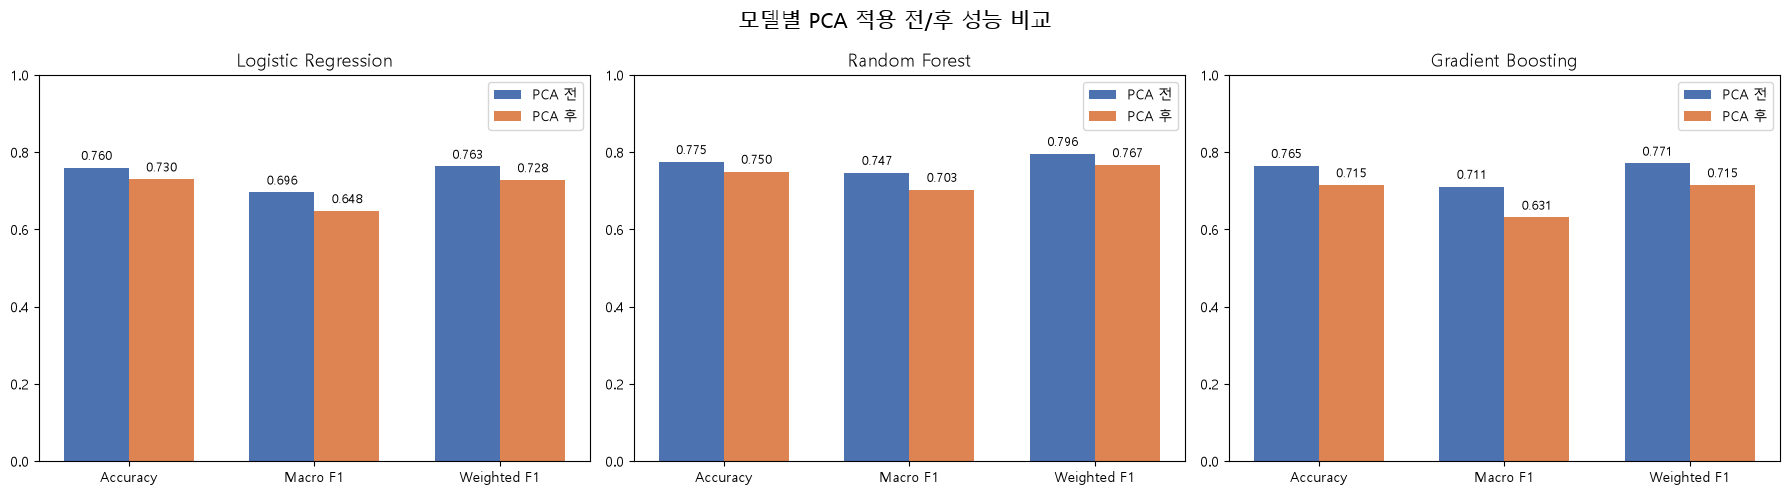

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ── 원본 변수 vs PCA 결과 정리 ────────────────────────────────
comparison_full = pd.DataFrame({
    'Accuracy':    [0.760, 0.775, 0.765],
    'Macro F1':    [0.696, 0.747, 0.711],
    'Weighted F1': [0.763, 0.796, 0.771]
}, index=['Logistic Regression', 'Random Forest', 'Gradient Boosting'])

comparison_pca = pd.DataFrame({
    'Accuracy':    [0.730, 0.750, 0.715],
    'Macro F1':    [0.648, 0.703, 0.631],
    'Weighted F1': [0.728, 0.767, 0.715]
}, index=['Logistic Regression', 'Random Forest', 'Gradient Boosting'])

# ── 모델별 그래프 (3개 서브플롯) ──────────────────────────────
metrics = ['Accuracy', 'Macro F1', 'Weighted F1']
models = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, model in enumerate(models):
    before = comparison_full.loc[model, metrics].values
    after = comparison_pca.loc[model, metrics].values

    x = np.arange(len(metrics))
    width = 0.35

    axes[i].bar(x - width/2, before, width, label='PCA 전', color='#4C72B0')
    axes[i].bar(x + width/2, after, width, label='PCA 후', color='#DD8452')

    axes[i].set_title(model, fontsize=13)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(metrics)
    axes[i].set_ylim(0, 1)
    axes[i].legend()

    # 값 라벨 표시
    for j, (b, a) in enumerate(zip(before, after)):
        axes[i].text(j - width/2, b + 0.02, f'{b:.3f}', ha='center', fontsize=9)
        axes[i].text(j + width/2, a + 0.02, f'{a:.3f}', ha='center', fontsize=9)

plt.suptitle('모델별 PCA 적용 전/후 성능 비교', fontsize=15)
plt.tight_layout()
plt.show()